![Original climate-globe illustration introducing Warm water, unusual water; illustrative, not a data map](assets/atlas-splash.png)

# 23 · Warm water, unusual water

**Guiding question:** Is the hottest month also the most anomalous month?

**Data:** Real C3S/ECMWF ERA5 Climate Pulse CSV snapshots retrieved 2026-11-20; CC BY 4.0  
**Time:** 20–35 minutes · **Prerequisites:** basic Python; run cells from top to bottom.  
**Author:** JupyterLite-C3S-Atlas contributors (AI assisted) · **Created/updated:** 2026-11-20  
**Inputs:** bundled reference files and/or seeded examples specified below. **Outputs:** tables, figures, and any explicitly named local exports; source data are not modified.  
**Runtime:** Python/Pyodide; NumPy, pandas, Matplotlib, Plotly; versions and tests are recorded in the validation report.  
**Change log:** initial educational chapter. **Contact:** [repository issues](https://github.com/jltobias/JupyterLite-C3S-Atlas/issues).

[Open in JupyterLite Lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/lite/lab/index.html?path=23-pulse-baselines.ipynb) · [Official Atlas](https://atlas.climate.copernicus.eu/)


## Read the evidence

Absolute temperature describes the water; anomaly describes its departure
        from a reference climate for the same calendar month. Seasonal structure can
        make the largest absolute temperature occur at a different time from the largest
        anomaly. The source supplies both quantities and its 1991–2020 climatology.

        Verify that subtraction reproduces the published anomaly within rounding.
        Then compare equal calendar months across event years. A different baseline
        changes the zero point; it does not change the underlying absolute SST. Neither
        a regional anomaly nor a single warm month measures a sustained global warming level.

## Start the browser lab

Run this setup cell once. First load needs internet for the Python runtime and packages. The remaining lesson uses bundled data. If a 3D view is unavailable, use the 2D/table alternative. Download your edited notebook before clearing browser storage.

In [1]:
# Install only in the browser kernel; desktop dependencies come from requirements.txt.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "pandas", "matplotlib", "plotly==6.5.0"])

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from atlas_helpers import (
    DATA, SYNTHETIC, COLORS, show, monthly_demo, anomalies, regular_grid,
    area_mean, coastlines, map_figure, globe_figure, warming_levels, load_monthly_csv,
)
print("Ready. Browser edits live in this browser; download work you want to keep.")


Ready. Browser edits live in this browser; download work you want to keep.


## Check the arithmetic and seasonal cycle

Maximum rounding residual (°C): 0.00010000000000309761


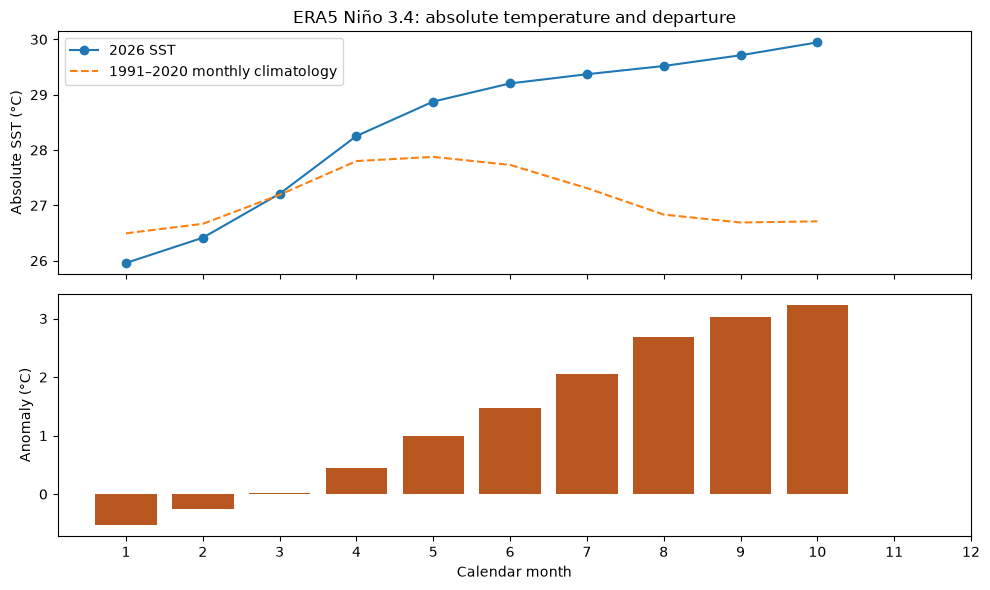

In [2]:
from pulse_helpers import (
    load_pulse, complete_months, rank_same_month, region_rings, region_geojson,
    region_map, region_globe, REGIONS, ANOM, REL, CREDIT, BASE,
)
df = load_pulse()
residual = df.sst - df.clim_1991_2020 - df[ANOM]
print("Maximum rounding residual (°C):", abs(residual).max())
recent = df[df.year == 2026]
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(recent.month, recent.sst, "o-", label="2026 SST")
axes[0].plot(recent.month, recent.clim_1991_2020, "--", label="1991–2020 monthly climatology")
axes[0].set(ylabel="Absolute SST (°C)", title="ERA5 Niño 3.4: absolute temperature and departure")
axes[0].legend()
axes[1].bar(recent.month, recent[ANOM], color="#b95721")
axes[1].set(xlabel="Calendar month", ylabel="Anomaly (°C)", xticks=range(1,13))
plt.tight_layout(); plt.show()

## Compare matching months, with no invented future values

In [3]:
years = [1982, 1997, 2015, 2023, 2026]
fig = go.Figure()
for year in years:
    part = df[df.year == year]
    fig.add_trace(go.Scatter(x=part.month, y=part[ANOM], mode="lines+markers", name=str(year)))
fig.update_layout(title="ERA5 Niño 3.4 · published monthly anomalies", xaxis=dict(title="Month", dtick=1, range=[1,12]), yaxis_title="°C relative to 1991–2020")
show(fig)
display(df.loc[df.groupby("year")[ANOM].idxmax(), ["year", "month", ANOM]].tail())

Figure({
    'data': [{'mode': 'lines+markers',
              'name': '1982',
              'type': 'scatter',
              'x': {'bdata': 'AQAAAAIAAAADAAAABAAAAAUAAAAGAAAABwAAAAgAAAAJAAAACgAAAAsAAAAMAAAA', 'dtype': 'i4'},
              'y': {'bdata': ('LbKd76fGy79wXwfOGVHCv921hHzQs6' ... 'uxv+yeAEB3vp8aL90DQCZTBaOSugVA'),
                    'dtype': 'f8'}},
             {'mode': 'lines+markers',
              'name': '1997',
              'type': 'scatter',
              'x': {'bdata': 'AQAAAAIAAAADAAAABAAAAAUAAAAGAAAABwAAAAgAAAAJAAAACgAAAAsAAAAMAAAA', 'dtype': 'i4'},
              'y': {'bdata': ('u7iNBvAW5r9ZF7fRAN7av6W9wRcmU9' ... 'ts5/upBEAnwoanV8oFQM9m1edqqwZA'),
                    'dtype': 'f8'}},
             {'mode': 'lines+markers',
              'name': '2015',
              'type': 'scatter',
              'x': {'bdata': 'AQAAAAIAAAADAAAABAAAAAUAAAAGAAAABwAAAAgAAAAJAAAACgAAAAsAAAAMAAAA', 'dtype': 'i4'},
              'y': {'bdata': ('fGEyVTAq4T9NFYxK6gTiP9O84xQdyd' ... 'qSy3/IAkCe76fGS7cFQC7/If329QRA'),
                    'dtype': 'f8'}},
             {'mode': 'lines+markers',
              'name': '2023',
              'type': 'scatter',
              'x': {'bdata': 'AQAAAAIAAAADAAAABAAAAAUAAAAGAAAABwAAAAgAAAAJAAAACgAAAAsAAAAMAAAA', 'dtype': 'i4'},
              'y': {'bdata': ('NIC3QILi5b/qBDQRNjzdv2EyVTAqqT' ... 'a+nxov+j9+HThnRGn9P02EDU+vFABA'),
                    'dtype': 'f8'}},
             {'mode': 'lines+markers',
              'name': '2026',
              'type': 'scatter',
              'x': {'bdata': 'AQAAAAIAAAADAAAABAAAAAUAAAAGAAAABwAAAAgAAAAJAAAACgAAAA==', 'dtype': 'i4'},
              'y': {'bdata': ('MEymCkYl4b/3Bl+YTBXQv0hQ/Bhz15' ... 'ts53sFQFtCPujZLAhAx0s3iUHgCUA='),
                    'dtype': 'f8'}}],
    'layout': {'font': {'size': 14},
               'height': 470,
               'margin': {'b': 65, 'l': 65, 'r': 45, 't': 90},
               'template': '...',
               'title': {'text': 'ERA5 Niño 3.4 · published monthly anomalies'},
               'xaxis': {'dtick': 1, 'range': [1, 12], 'title': {'text': 'Month'}},
               'yaxis': {'title': {'text': '°C relative to 1991–2020'}}}
})

,year,month,anom_1991_2020
522,2022,7,-0.6825
539,2023,12,2.0101
540,2024,1,1.8304
554,2025,3,0.0752
573,2026,10,3.2345


## Open the same selection in official Climate Pulse

In [4]:
from app_helpers import pulse_link
from IPython.display import Markdown
url = pulse_link(region="nino34", aggregation="monthly", date="2026-10-01", quantity="absolute")
display(Markdown(f"[Open this selection in the official Climate Pulse app]({url})"))
print("Check the displayed region, date, aggregation, quantity, and baseline after opening.")
print("The official app may update or revise its data. The notebook keeps its dated snapshot.")
print("For a gridded map, use Pulse’s map view and probe; a relative Niño index is a regional time series.")

[Open this selection in the official Climate Pulse app](https://pulse.climate.copernicus.eu/?variable=sst&region=nino-3-4&series=absolute&map=anomaly&aggregation=monthly&date=2026-10-01)

Check the displayed region, date, aggregation, quantity, and baseline after opening.
The official app may update or revise its data. The notebook keeps its dated snapshot.
For a gridded map, use Pulse’s map view and probe; a relative Niño index is a regional time series.


## Try it and explain

Try a different set of comparison years. Which months exist for every selected year? Restrict a comparison to that common window.

**Interpretation check:** A truncated current year is not a full annual cycle. Missing November and December values must remain absent, not be set to zero or extrapolated.

## Transfer to the official tools

Recreate the Niño 3.4 comparison in Pulse using monthly anomalies. Compare the legend, reference period, and selected years with this notebook.

Record the selections, source version, units, periods, and uncertainty legend. These independent lessons do not duplicate every production workflow in the official tools.

## Sources and credit

- [C3S Atlas dataset and DOI](https://doi.org/10.24381/cds.h35hb680)
- [CSIC / Predictia Atlas user guide](https://confluence.ecmwf.int/spaces/CKB/pages/394237545/Copernicus+Interactive+Climate+Atlas+User+Guide)
- [Official C3S Atlas User Tools and contributors](https://ecmwf-projects.github.io/c3s-atlas/)
- [C3S Climate Pulse 2.0 announcement (10 November 2026)](https://climate.copernicus.eu/new-version-climate-pulse-provides-new-monitoring-el-nino-conditions)
- [Climate Pulse FAQs and methodology](https://pulse.climate.copernicus.eu/faqs)
- [Climate Pulse credits and citations](https://pulse.climate.copernicus.eu/credits)
- [ERA5 monthly data: C3S/ECMWF and ERA5 contributors](https://doi.org/10.24381/cds.f17050d7)
- [Hersbach et al. (2020): The ERA5 global reanalysis](https://doi.org/10.1002/qj.3803)
- [Official Climate Pulse application](https://pulse.climate.copernicus.eu/)

Original teaching text and code; original AI-generated splash illustration. Real reference files retain their source licences. Synthetic examples are not Copernicus measurements. See [credits](credits.md) and [data guide](data-guide.md).

**Continue:** [ENSO against a warming ocean](24-relative-enso.ipynb)